# Exploring one con2phys recording

Set `MOUSE` in the first code cell to look at any of the 18 mice.

Each folder `py-files/<mouse>/` holds one recording session. The data comes in two separate kinds:

| | **Units** (neurons) | **Channels** (recording sites) |
|---|---|---|
| What it is | One neuron isolated by spike sorting (a "cluster") | One physical contact on the Neuropixels probe |
| Files | `spikes.npy`, `clusters.npy`, `brain_area.npy`, `waveforms.npy` | `lfp_1.npy`, `lfp_2.npy`, `lfp_3.npy` |
| One row per... | unit → `waveforms` is `[n_units × 128]` | channel → `lfp_k` is `[n_channels × n_timepoints]` |
| Sampling rate | waveforms: 30 kHz | LFP: 500 Hz |

Units and channels are **not** the same thing. A neuron's spike shows up on several neighbouring channels.
`waveforms.npy` keeps only the channel where each unit was detected best, so it has one row per **unit**.
For example, mouse 1 has 88 units, so `waveforms` has 88 rows, just like `cluster_id`. Its LFP has 28 + 25 + 47 = 100 channels.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from c2p import AREAS, AREA_COLORS, FS_LFP, FS_WAVEFORM, Recording, mice

MOUSE = 1          # change to explore another mouse (1-18)
print("available mice:", mice())

available mice: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]


## 1. One object per recording

`Recording`, defined in `c2p/data.py`, groups everything from one folder and adds a few helpers that take care of the index bookkeeping.
It's shared by all the question notebooks.

- `rec.units` is a table with one row per unit: `mouse`, `cluster_id`, `area`, number of spikes and firing rate.
- `rec.spike_times(cid)` returns the spike times (s) of one unit.
- `rec.waveform(cid)` returns the average waveform of one unit.
- `rec.lfp[area]` holds the LFP of one area, `[channels × time]`. It is opened with `mmap_mode="r"`, so the 1.3 GB stays on disk until it is sliced.
- `rec.trials` is the trial table.

Run `Recording??` in a cell to see its code.

In [2]:
rec = Recording.load(MOUSE)
print(f"mouse {rec.mouse}: {len(rec.units)} units, {len(rec.spike_times_all):,} spikes, "
      f"{rec.duration_s / 60:.1f} min recorded, {len(rec.trials)} trials")
rec.summary()

mouse 1: 88 units, 2,525,186 spikes, 55.8 min recorded, 408 trials


,n_units,median_rate_hz,n_lfp_channels
area,,,
1,59,8.060945,28
2,22,3.201907,25
3,7,11.273445,47


In [3]:
rec.units.head()

,mouse,cluster_id,area,n_spikes,rate_hz
0,1,383,1,14747,4.400813
1,1,386,1,21102,6.297277
2,1,388,1,27012,8.060945
3,1,389,1,7535,2.248601
4,1,391,1,9683,2.889609


## 2. What a waveform is

When a neuron fires, the voltage at the nearest probe contact drops sharply for less than a millisecond and then recovers.
The raw signal was sampled 30,000 times per second. For every spike of a unit, a window of **128 samples (≈ 4.3 ms)** was cut out around the spike time,
and all those windows were averaged. That average is one row of `waveforms`.

So a waveform shows **what the unit's spikes look like**, not when they happened. The *when* is in `spikes.npy`.

Below is one unit. Each dot is one sample (1/30,000 s ≈ 0.033 ms apart). Time 0 is the trough, the most negative point, which marks the moment of the spike.

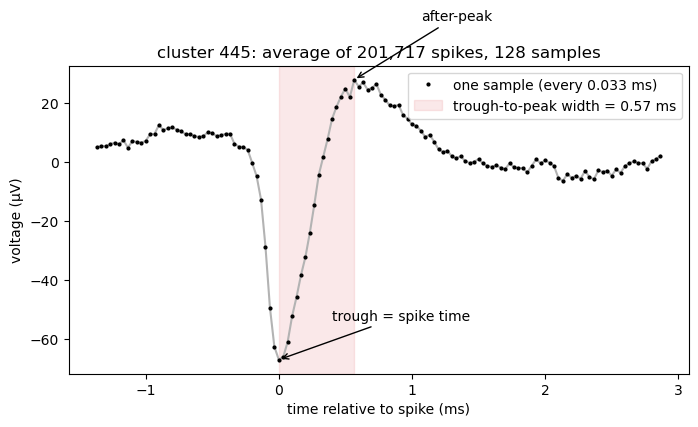

In [4]:
def waveform_time_ms(wf):
    # Time axis in ms with 0 at the trough
    return (np.arange(len(wf)) - np.argmin(wf)) / FS_WAVEFORM * 1000

def trough_to_peak_ms(wf):
    # Time from the trough to the following maximum: a standard measure of spike width
    i_trough = np.argmin(wf)
    i_peak = i_trough + np.argmax(wf[i_trough:])
    return (i_peak - i_trough) / FS_WAVEFORM * 1000

cid = rec.units.sort_values("n_spikes").cluster_id.iloc[-1]   # the unit with most spikes
wf = rec.waveform(cid) * 1e6   # values look like volts; shown in µV (the site does not state the unit)
t = waveform_time_ms(wf)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, wf, "-", color="0.7")
ax.plot(t, wf, ".", color="k", ms=4, label="one sample (every 0.033 ms)")
i_tr = np.argmin(wf); i_pk = i_tr + np.argmax(wf[i_tr:])
ax.annotate("trough = spike time", (t[i_tr], wf[i_tr]), xytext=(0.4, wf[i_tr] * 0.8),
            arrowprops=dict(arrowstyle="->"))
ax.annotate("after-peak", (t[i_pk], wf[i_pk]), xytext=(t[i_pk] + 0.5, wf[i_pk] + 20),
            arrowprops=dict(arrowstyle="->"))
ax.axvspan(t[i_tr], t[i_pk], color="tab:red", alpha=0.1,
           label=f"trough-to-peak width = {trough_to_peak_ms(wf):.2f} ms")
ax.set(xlabel="time relative to spike (ms)", ylabel="voltage (µV)",
       title=f"cluster {cid}: average of {rec.units.set_index('cluster_id').n_spikes[cid]:,} spikes, 128 samples")
ax.legend(loc="upper right");

### Why 30 kHz? Compare with the LFP

The LFP is sampled at 500 Hz, one point every 2 ms. Over the whole 4.3 ms waveform window it would get only 2–3 points,
which is far too coarse to see a spike. That's why spikes are detected in the 30 kHz raw signal, and why the waveform is the only high-resolution signal in this dataset.

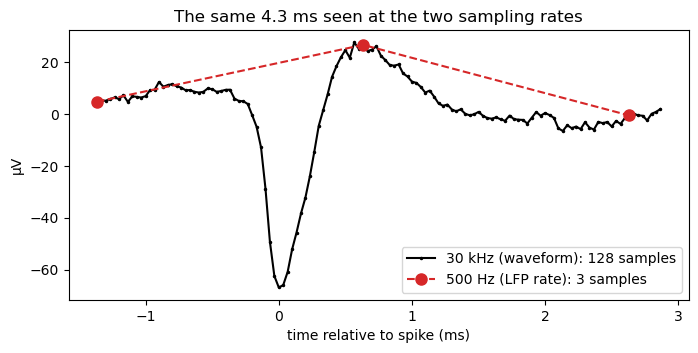

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t, wf, ".-", color="k", ms=3, label="30 kHz (waveform): 128 samples")
lfp_idx = np.arange(0, len(wf), FS_WAVEFORM // FS_LFP)
ax.plot(t[lfp_idx], wf[lfp_idx], "o--", color="tab:red", ms=8, label=f"500 Hz (LFP rate): {len(lfp_idx)} samples")
ax.set(xlabel="time relative to spike (ms)", ylabel="µV", title="The same 4.3 ms seen at the two sampling rates")
ax.legend();

### Shape vs. timing

The two pieces of information about a unit live in different files:
- **Timing** (`spikes.npy` + `clusters.npy`): a list of moments at which the unit fired.
- **Shape** (`waveforms.npy`): what each of those spikes looks like on average.

The top panel shows 2 seconds of the unit's spike times. The bottom panel zooms into 20 ms and draws the average shape at each spike time.
This is an illustration. The raw voltage trace isn't in the dataset, so the real individual spikes would differ a bit from the average.

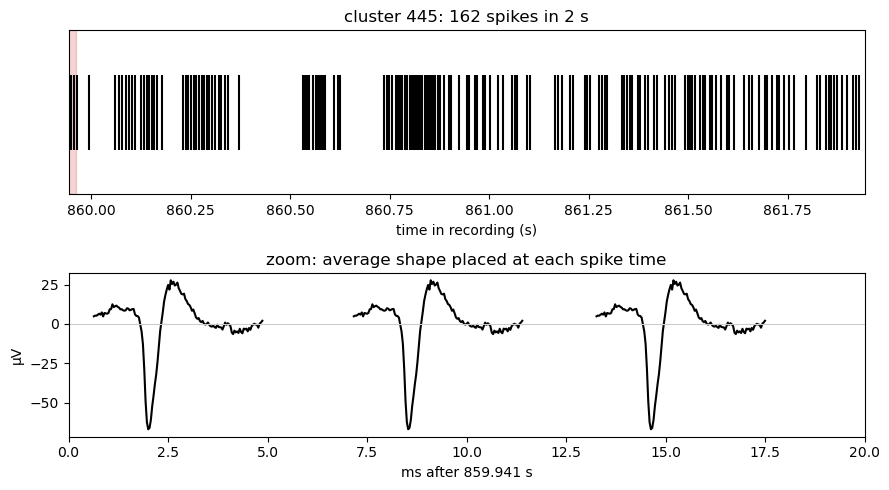

In [6]:
st = rec.spike_times(cid)
t0 = st[len(st) // 2]            # somewhere in the middle of the recording
win = (t0, t0 + 2.0)
in_win = st[(st >= win[0]) & (st < win[1])]

zoom = (in_win[0] - 0.002, in_win[0] + 0.018)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5))
a1.eventplot(in_win, color="k")
a1.axvspan(*zoom, color="tab:red", alpha=0.2)
a1.set(xlim=win, yticks=[], xlabel="time in recording (s)", title=f"cluster {cid}: {len(in_win)} spikes in 2 s")

for s in st[(st >= zoom[0]) & (st < zoom[1])]:
    a2.plot((s + t / 1000 - zoom[0]) * 1000, wf, color="k")
a2.axhline(0, color="0.8", lw=0.8)
a2.set(xlim=(0, 20), xlabel=f"ms after {zoom[0]:.3f} s", ylabel="µV", title="zoom: average shape placed at each spike time")
fig.tight_layout()

## 3. All waveforms at once

Each row of the heatmap is one unit, sorted by area and then by width. Each trace is scaled so its trough is −1, which makes the shapes comparable regardless of amplitude.
The width histogram often shows two groups: **narrow** spikes (≲ 0.4 ms, often fast-spiking interneurons) and **broad** spikes (often pyramidal cells).
Treat that split as a rule of thumb, not a ground truth.

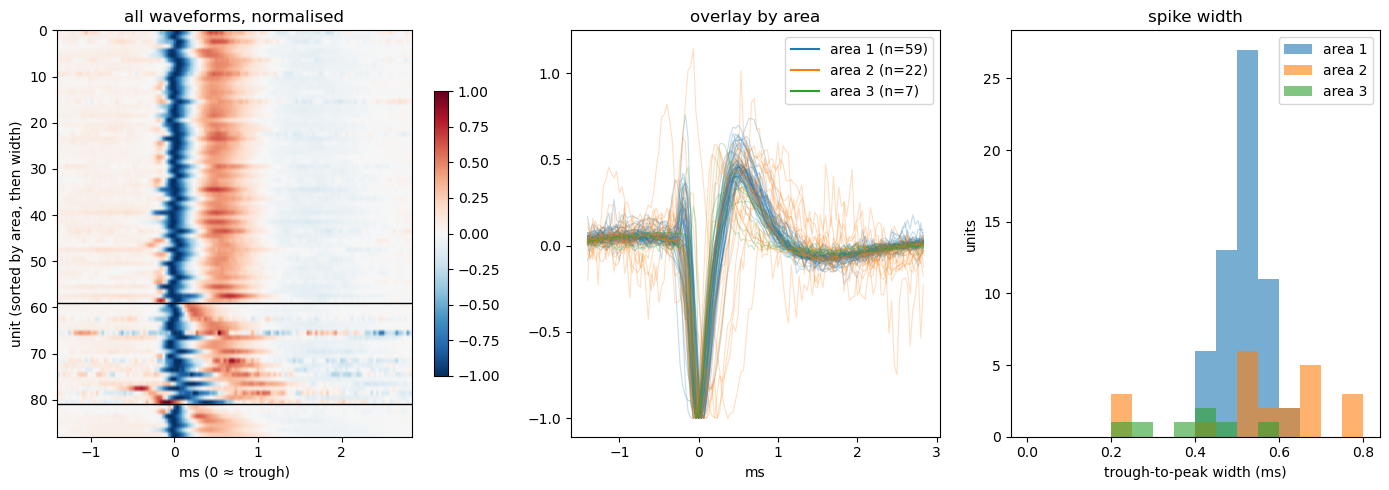

In [7]:
wf_all = rec.waveforms
norm = wf_all / -wf_all.min(axis=1, keepdims=True)        # trough -> -1
rec.units["width_ms"] = [trough_to_peak_ms(w) for w in wf_all]
rec.units["amplitude_uv"] = (wf_all.max(axis=1) - wf_all.min(axis=1)) * 1e6

order = rec.units.sort_values(["area", "width_ms"]).index
t_all = (np.arange(wf_all.shape[1]) - np.median(np.argmin(wf_all, axis=1))) / FS_WAVEFORM * 1000

fig, axs = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
im = axs[0].imshow(norm[order], aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1,
                   extent=[t_all[0], t_all[-1], len(order), 0])
for b in np.cumsum(rec.units.area.value_counts().sort_index().values)[:-1]:
    axs[0].axhline(b, color="k", lw=1)
axs[0].set(xlabel="ms (0 ≈ trough)", ylabel="unit (sorted by area, then width)", title="all waveforms, normalised")
fig.colorbar(im, ax=axs[0], shrink=0.7)

for a in AREAS:
    rows = rec.units.index[rec.units.area == a]
    axs[1].plot(t_all, norm[rows].T, color=AREA_COLORS[a], alpha=0.25, lw=0.8)
    axs[1].plot([], [], color=AREA_COLORS[a], label=f"area {a} (n={len(rows)})")
axs[1].set(xlabel="ms", title="overlay by area"); axs[1].legend()

bins = np.arange(0, rec.units.width_ms.max() + 0.05, 0.05)
for a in AREAS:
    axs[2].hist(rec.units.width_ms[rec.units.area == a], bins=bins, color=AREA_COLORS[a], alpha=0.6, label=f"area {a}")
axs[2].set(xlabel="trough-to-peak width (ms)", ylabel="units", title="spike width"); axs[2].legend()
fig.tight_layout()

In [8]:
rec.units.groupby("area")[["width_ms", "amplitude_uv", "rate_hz"]].describe().round(2).T

area                     1       2       3
width_ms     count   59.00   22.00    7.00
             mean     0.51    0.56    0.40
             std      0.05    0.18    0.12
             min      0.40    0.20    0.23
             25%      0.47    0.53    0.33
             50%      0.50    0.60    0.40
             75%      0.53    0.67    0.45
             max      0.63    0.80    0.60
amplitude_uv count   59.00   22.00    7.00
             mean   163.13  104.12  278.80
             std     71.34   89.65  303.67
             min     43.00   13.57   49.04
             25%    100.44   26.26  104.94
             50%    165.47   63.83  144.58
             75%    207.49  167.69  344.55
             max    339.48  303.49  859.02
rate_hz      count   59.00   22.00    7.00
             mean     9.30    5.69   11.35
             std      8.14    6.72    8.44
             min      0.30    0.68    2.59
             25%      4.14    1.93    3.50
             50%      8.06    3.20   11.27
             75%     11.66    6.23   17.87
             max     60.20   29.63   22.85

## 4. Spikes and LFP over the same few seconds

This puts everything on the shared time axis (seconds since the recording began). The top panel shows the spikes of every unit, grouped by area, with trial events marked.
The bottom panel shows a few LFP channels from each area. Change `T_START` to move the window.

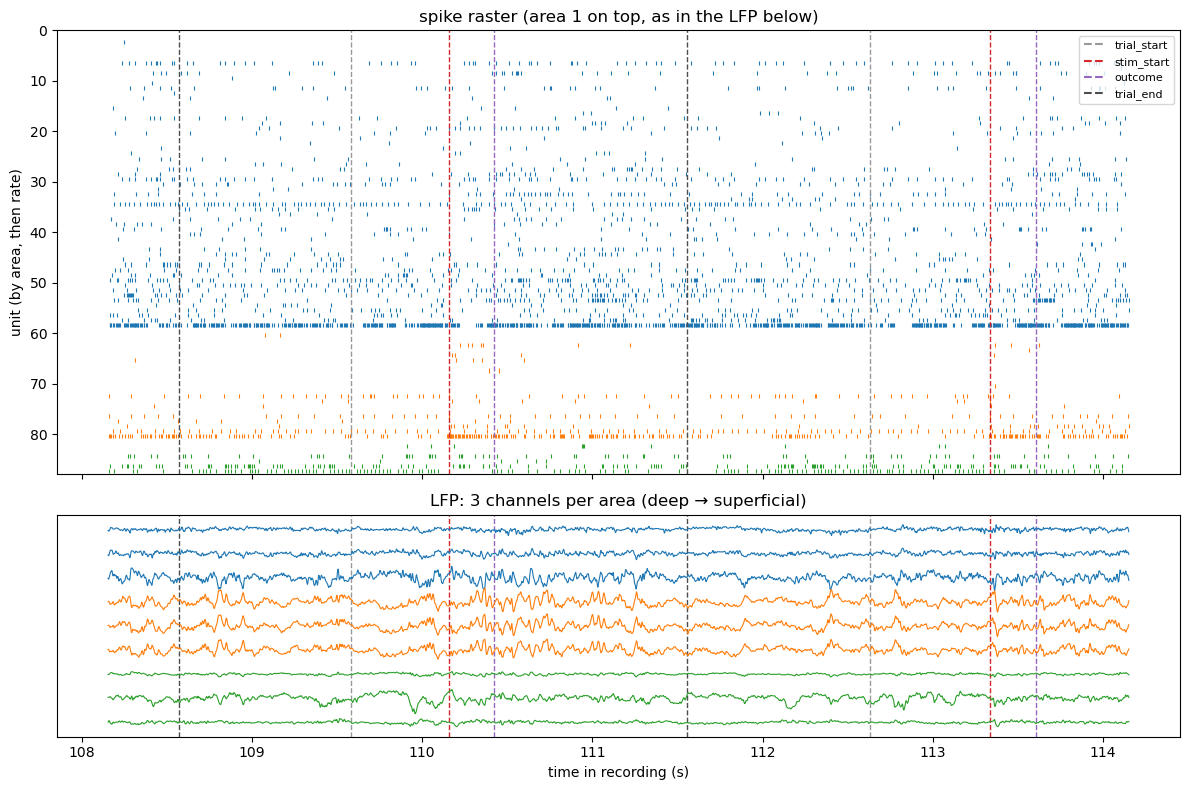

In [9]:
T_START, T_LEN = rec.trials.stim_start.iloc[10] - 2, 6.0
t_win = (T_START, T_START + T_LEN)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
units_sorted = rec.units.sort_values(["area", "rate_hz"])
for row, (_, u) in enumerate(units_sorted.iterrows()):
    st = rec.spike_times(u.cluster_id)
    st = st[(st >= t_win[0]) & (st < t_win[1])]
    a1.vlines(st, row, row + 0.8, color=AREA_COLORS[u.area], lw=0.8)
a1.set(ylabel="unit (by area, then rate)", ylim=(len(units_sorted), 0), title="spike raster (area 1 on top, as in the LFP below)")

events = {"trial_start": "0.6", "stim_start": "tab:red", "outcome": "tab:purple", "trial_end": "0.3"}
for col, c in events.items():
    for x in rec.trials[col][(rec.trials[col] >= t_win[0]) & (rec.trials[col] < t_win[1])]:
        for ax in (a1, a2):
            ax.axvline(x, color=c, ls="--", lw=1)
    a1.plot([], [], color=c, ls="--", label=col)
a1.legend(loc="upper right", fontsize=8)

i0, i1 = int(t_win[0] * FS_LFP), int(t_win[1] * FS_LFP)
t_lfp = np.arange(i0, i1) / FS_LFP
offset = 0
for a in AREAS:
    chans = np.linspace(0, rec.lfp[a].shape[0] - 1, 3).astype(int)   # deepest, middle, most superficial
    x = np.asarray(rec.lfp[a][chans, i0:i1])
    scale = np.ptp(x) or 1
    for k, ch in enumerate(chans):
        a2.plot(t_lfp, x[k] / scale - offset, color=AREA_COLORS[a], lw=0.8)
        offset += 1
a2.set(xlabel="time in recording (s)", yticks=[], title="LFP: 3 channels per area (deep → superficial)")
fig.tight_layout()

## 5. All LFP channels, deep → superficial

Every row of `lfp_k` is one recording site. Within an area, the sites are contiguous along the probe, and row 0 is the **deepest**.
Here every channel is drawn in the same 6 s window as above, with one scale per area, so that amplitudes can be compared across depth.
The site gives 20 µm between recording sites but also says only every other channel is kept, so I label rows by index rather than converting them to µm.

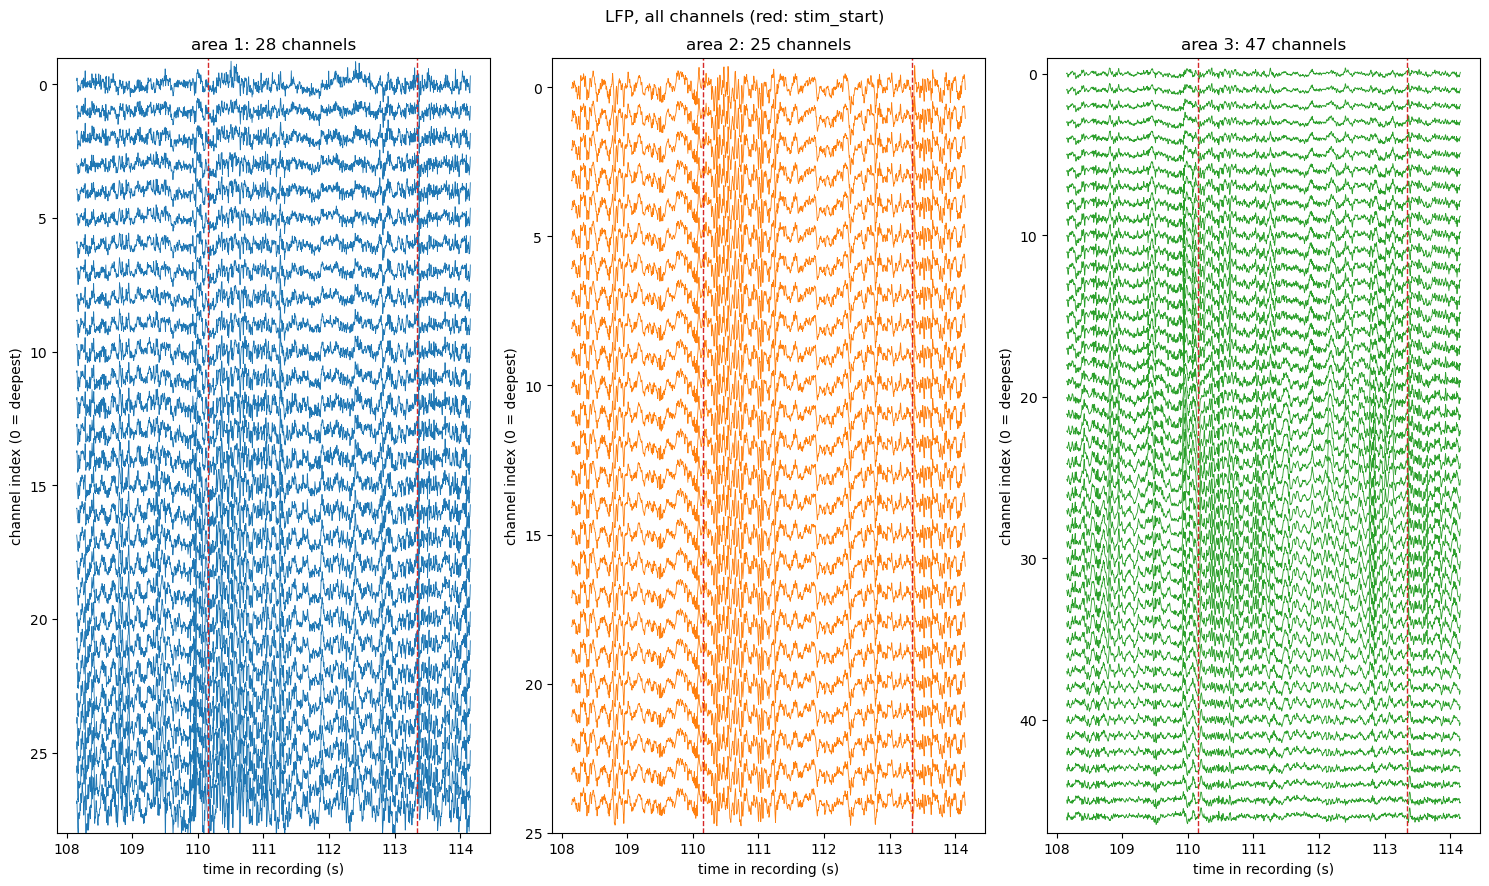

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 9), sharex=True)
for ax, a in zip(axs, AREAS):
    x = np.asarray(rec.lfp[a][:, i0:i1])
    x = x - x.mean(axis=1, keepdims=True)
    step = 4 * np.median(x.std(axis=1))          # vertical spacing between traces
    for ch in range(x.shape[0]):
        ax.plot(t_lfp, x[ch] / step + ch, color=AREA_COLORS[a], lw=0.6)
    for x_ev in rec.trials.stim_start[(rec.trials.stim_start >= t_win[0]) & (rec.trials.stim_start < t_win[1])]:
        ax.axvline(x_ev, color="tab:red", ls="--", lw=1)
    ax.set(ylim=(x.shape[0], -1), title=f"area {a}: {x.shape[0]} channels",
           xlabel="time in recording (s)", ylabel="channel index (0 = deepest)")
fig.suptitle("LFP, all channels (red: stim_start)")
fig.tight_layout()

## 6. What the LFP is good for

Spikes come from single neurons. The **LFP** is the slow part (below about 250 Hz here) of the voltage at each site.
It's dominated by synaptic currents summed over thousands of cells near the contact, so it reflects the **input and coordinated activity of a population** rather than the output of one cell. In practice it's used to:

1. **See responses to events.** Average the LFP around `stim_start` (an evoked potential) to see when and at which depth an area responds.
2. **Measure oscillations** (theta, beta, gamma, ...) with a power spectrum, and compare them across areas or conditions.
3. **Relate spikes to the population rhythm.** Spike–LFP coupling, such as the spike-triggered LFP average below, or the phase of an oscillation at which a neuron fires.
4. **Study communication between areas.** Coherence, Granger causality and similar measures between `lfp_1`, `lfp_2` and `lfp_3`.
5. **Locate the layers.** Sign flips across depth and current source density (CSD) analysis show where currents enter and leave.

All three plots below use one operation: cut windows of a signal around a list of event times, then average them.
The event can be a stimulus, or a spike. Averaging around spikes is exactly how `waveforms.npy` was made from the raw 30 kHz signal (a spike-triggered average).

In [11]:
def event_locked_average(lfp, event_times, t_before, t_after, fs=FS_LFP):
    # Mean of lfp[:, t-t_before : t+t_after] over events. Returns (time axis in s, [channels, time]).
    n_pre, n_post = int(t_before * fs), int(t_after * fs)
    idx = np.round(np.asarray(event_times) * fs).astype(int)
    idx = idx[(idx - n_pre >= 0) & (idx + n_post <= lfp.shape[1])]
    acc = np.zeros((lfp.shape[0], n_pre + n_post))
    for i in idx:                                # loop keeps memory small with the memory-mapped LFP
        acc += lfp[:, i - n_pre:i + n_post]
    return np.arange(-n_pre, n_post) / fs, acc / len(idx)

### 6a. Stimulus-evoked LFP

This averages all trials, aligned to `stim_start`, for every channel. The baseline (the 0.5 s before the stimulus) is subtracted.

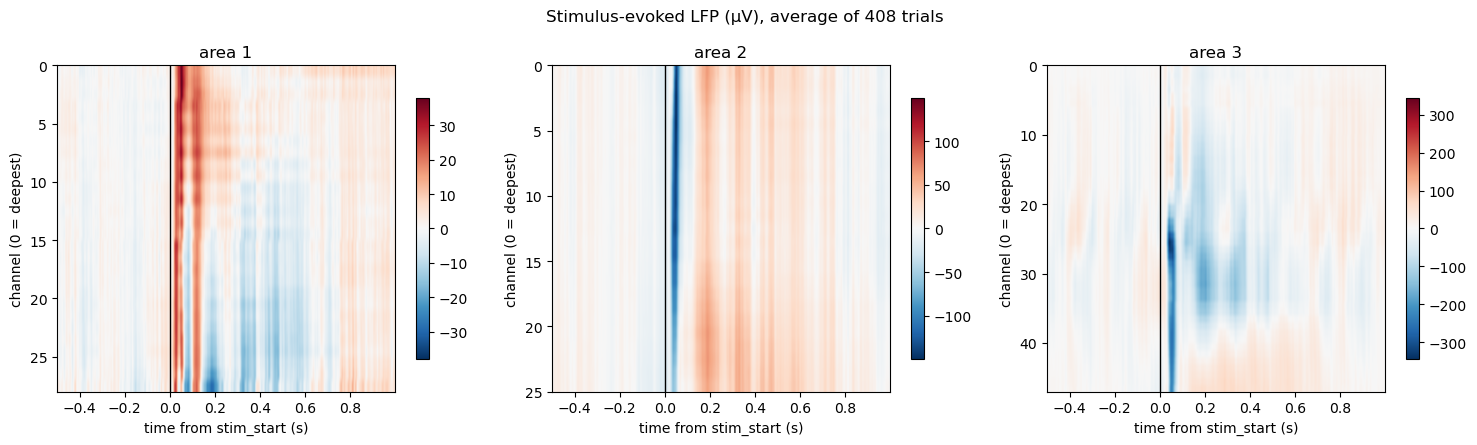

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, a in zip(axs, AREAS):
    t_ev, erp = event_locked_average(rec.lfp[a], rec.trials.stim_start, 0.5, 1.0)
    erp = (erp - erp[:, t_ev < 0].mean(axis=1, keepdims=True)) * 1e6   # values look like volts -> µV
    lim = np.abs(erp).max()
    im = ax.imshow(erp, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim,
                   extent=[t_ev[0], t_ev[-1], erp.shape[0], 0])
    ax.axvline(0, color="k", lw=1)
    ax.set(title=f"area {a}", xlabel="time from stim_start (s)", ylabel="channel (0 = deepest)")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f"Stimulus-evoked LFP (µV), average of {len(rec.trials)} trials")
fig.tight_layout()

### 6b. Power spectrum: which rhythms are present

Welch spectrum of 10 minutes from the middle of the recording, averaged over the channels of each area. The 500 Hz sampling rate means frequencies up to 250 Hz.

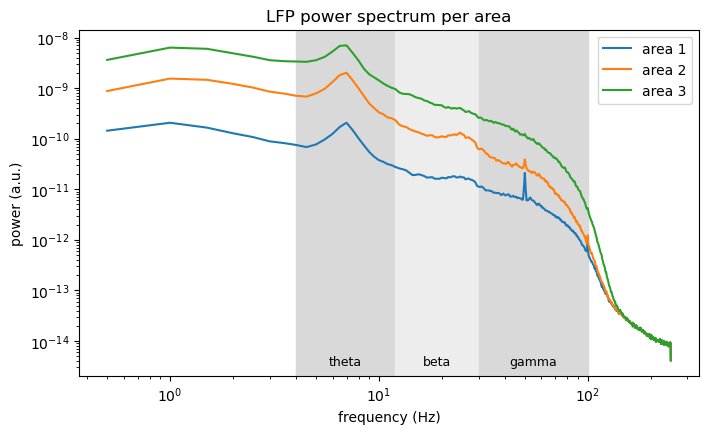

In [13]:
from scipy.signal import welch

mid = rec.lfp[1].shape[1] // 2
seg = slice(mid - 300 * FS_LFP, mid + 300 * FS_LFP)
fig, ax = plt.subplots(figsize=(8, 4.5))
for a in AREAS:
    f, pxx = welch(np.asarray(rec.lfp[a][:, seg]), fs=FS_LFP, nperseg=2 * FS_LFP, axis=1)
    ax.loglog(f[1:], pxx[:, 1:].mean(axis=0), color=AREA_COLORS[a], label=f"area {a}")
for (lo, hi), name, c in [((4, 12), "theta", "0.85"), ((12, 30), "beta", "0.93"), ((30, 100), "gamma", "0.85")]:
    ax.axvspan(lo, hi, color=c, zorder=0)
    ax.text(np.sqrt(lo * hi), 0.03, name, transform=ax.get_xaxis_transform(), ha="center", fontsize=9)
ax.set(xlabel="frequency (Hz)", ylabel="power (a.u.)", title="LFP power spectrum per area")
ax.legend();

### 6c. Spike-triggered LFP average

This is the same operation, but the events are the spikes of one unit. If a neuron tends to fire at a particular point of the population rhythm,
the average shows a structured wave around time 0. If it doesn't, the average looks like the one for random times: it shrinks towards flat noise.

Coupling varies a lot from neuron to neuron. So the first step scores every unit: the size of its spike-triggered average on the middle channel of its area,
divided by the size obtained from the same number of **random** times. A score of 1 means no coupling.

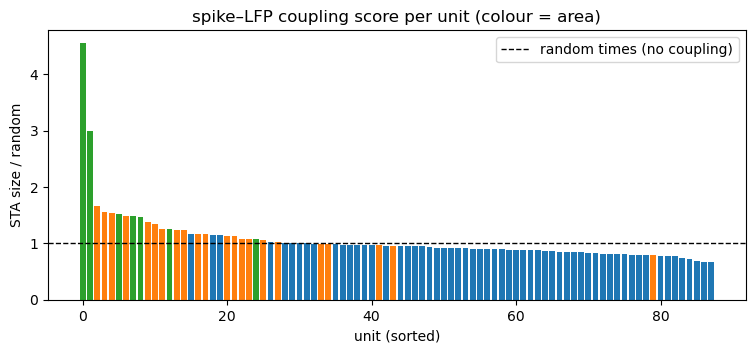

In [14]:
rng = np.random.default_rng(0)
N_EV = 1000                                              # spikes per unit used for the score
mid_ch = {a: np.asarray(rec.lfp[a][rec.lfp[a].shape[0] // 2])[None, :] for a in AREAS}   # one channel in RAM

def sta_size(lfp, times):
    _, avg = event_locked_average(lfp, times, 0.25, 0.25)
    return np.ptp(avg)

noise = {a: np.median([sta_size(mid_ch[a], rng.uniform(1, rec.duration_s - 1, N_EV)) for _ in range(20)])
         for a in AREAS}
scores = []
for _, u in rec.units.iterrows():
    st = rec.spike_times(u.cluster_id)
    st = rng.choice(st, size=min(N_EV, len(st)), replace=False)
    scores.append(sta_size(mid_ch[u.area], st) / noise[u.area])
rec.units["lfp_coupling"] = scores

fig, ax = plt.subplots(figsize=(9, 3.5))
s = rec.units.sort_values("lfp_coupling", ascending=False).reset_index(drop=True)
ax.bar(s.index, s.lfp_coupling, color=s.area.map(AREA_COLORS))
ax.axhline(1, color="k", ls="--", lw=1, label="random times (no coupling)")
ax.set(xlabel="unit (sorted)", ylabel="STA size / random", title="spike–LFP coupling score per unit (colour = area)")
ax.legend();

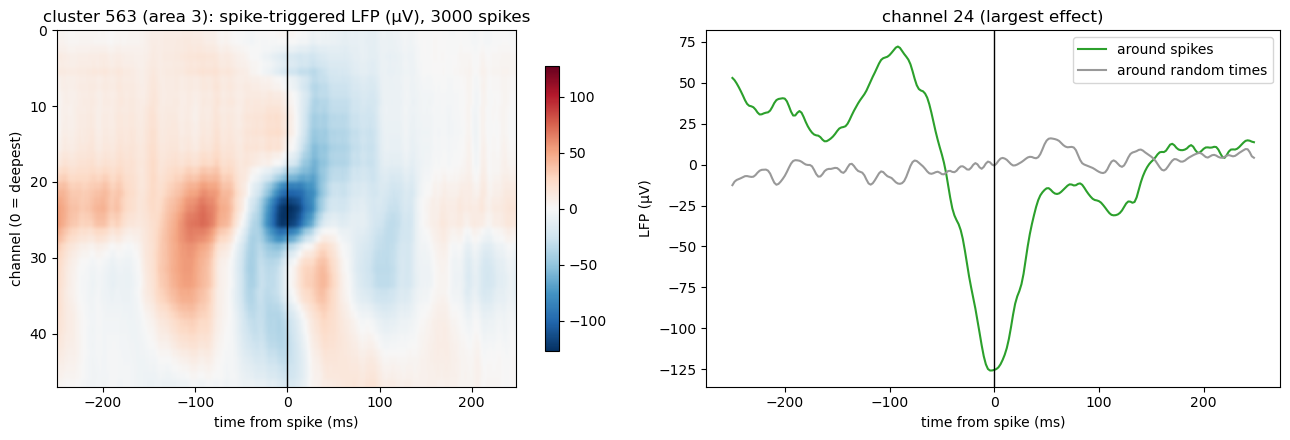

In [15]:
cid_c = rec.units.sort_values("lfp_coupling").cluster_id.iloc[-1]       # most coupled unit
area_c = rec.units.set_index("cluster_id").area[cid_c]
st = rec.spike_times(cid_c)
spk = rng.choice(st, size=min(3000, len(st)), replace=False)
rand = rng.uniform(1, rec.duration_s - 1, size=len(spk))

t_sta, sta = event_locked_average(rec.lfp[area_c], spk, 0.25, 0.25)
_, ctrl = event_locked_average(rec.lfp[area_c], rand, 0.25, 0.25)
sta = (sta - sta.mean(axis=1, keepdims=True)) * 1e6
ctrl = (ctrl - ctrl.mean(axis=1, keepdims=True)) * 1e6
best = np.argmax(np.ptp(sta, axis=1))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
lim = np.abs(sta).max()
im = a1.imshow(sta, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim,
               extent=[t_sta[0] * 1000, t_sta[-1] * 1000, sta.shape[0], 0])
a1.axvline(0, color="k", lw=1)
a1.set(title=f"cluster {cid_c} (area {area_c}): spike-triggered LFP (µV), {len(spk)} spikes",
       xlabel="time from spike (ms)", ylabel="channel (0 = deepest)")
fig.colorbar(im, ax=a1, shrink=0.8)

a2.plot(t_sta * 1000, sta[best], color=AREA_COLORS[area_c], label="around spikes")
a2.plot(t_sta * 1000, ctrl[best], color="0.6", label="around random times")
a2.axvline(0, color="k", lw=1)
a2.set(title=f"channel {best} (largest effect)", xlabel="time from spike (ms)", ylabel="LFP (µV)")
a2.legend()
fig.tight_layout()